# Análise exploratória e scripts computacionais de Formativa03-Grupo-08

- **Repositório:** `analise-de-dados-fundamentos`  
- **Tecnologias:** Pandas, NumPy  
- **Arquivo Original:** `Formativa03-Grupo-08`  

---


# VALIAÇÃO CRUZADA

### Importar bibliotecas

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from sklearn.naive_bayes import GaussianNB
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold

### Conectar com GoogleDrive

In [28]:
# Conectar com o Google Drive
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


### Variáveis de ambiente para arquivos e conversão para PDF
Alterar os caminhos de acordo com sua organização

In [29]:
# Path para pasta de DADOS
caminho_dados = '/content/gdrive/MyDrive/DADOS/'

# Path para pasta de PDF
caminho_pdf = '/content/gdrive/MyDrive/PDF/ADS'

# Nome do notebook
nome = 'Formativa03-Grupo-08'

### Leitura de dados de de treinamento
O dados no arquivo YTreinamento2.csv não foram utilizado na FORMATIVA do classificador GaussianMV porque o treinamento desse classificador é não supervisionado.<br>
Os dados são necessários para o classificador GaussianNB porque o seu treinamento é supervisionado.<br>
Os dados também necessários para a validação cruzada.

In [30]:
Xtre = np.loadtxt(caminho_dados + 'DadosTreinamento.csv', delimiter=',')
Ytre = np.loadtxt(caminho_dados + 'YTreinamento.csv', delimiter=',')

### Leitura dos dados de validação
Os dados do arquivo DaddosValidação2 são necessários para treinar o classificador GaussianMV.

In [31]:
# Leitura do arquivo com dados de validação
XYval = np.loadtxt(caminho_dados + 'DadosValidacao.csv', delimiter=',')
Xval = XYval[:,[0,1,2,3,4,5,6,7,8,9,10]]
Yval = XYval[:,11]

### Leitura dos dados de teste

In [32]:
XYtest = np.loadtxt(caminho_dados + 'DadosTeste.csv', delimiter=',')
X_test = XYtest[:,[0,1,2,3,4,5,6,7,8,9,10]]
Y_test = XYtest[:,11]

# Classificador GaussianNB
* Utilizar classificador GaussianNB para detecção de anomalias utilizando os dados de servidores em uma rede.
* Calcular as métricas de classificação e comparar com o relatório produzido pela biblioteca sklearn.
* Plotar a matriz de confusão
* Realizar validação cruzada método KFold

### Treinamento e previsão
* Criar classificador<br>
* Treinar com dados de treinamento utilizando a matriz com os dados de treinamento (Xtre) e o vetor com os rótulo de treinamento (Ytre)<br>
* Faz previsão utilizando os dados de teste (X_test)

In [33]:
# Treinamento e previsão
clf = GaussianNB()
clf.fit(Xtre, Ytre)
Y_prev = clf.predict(X_test)

#### Calcular e imprimir métricas

In [34]:
# Calcular e imprimir accurary
acc_teste_GNB = metrics.accuracy_score(Y_test, Y_prev)
print(acc_teste_GNB)
# Calcular a imprimir F1
F1_teste_GNB = metrics.f1_score(Y_test, Y_prev, average='weighted')
print(F1_teste_GNB)

0.9275
0.9122398828368976


#### Plotar matriz de confusão

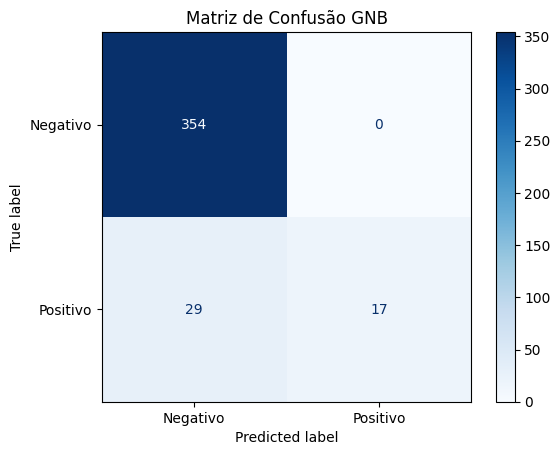

In [35]:
# Gerar a matriz de confusão
mc = confusion_matrix(Y_test, Y_prev)

# Definir os nomes das classes (opcional, mas recomendado para clareza)
classes = ['Negativo', 'Positivo']

disp = ConfusionMatrixDisplay(confusion_matrix=mc, display_labels=classes)
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de Confusão GNB')
plt.show()

### Validação Cruzada
#### Visualização do método Kfold
A biblioteca sklearn fornece a função Kfold que particiona o conjunto de dados de treinamento original nos subconjuntos de treinamento e teste para cada iteração.<br>

A função plot_cv_indices ilustra a partição dos índices das amostras que são utilizados em cada iteração para selecionar os subconjuntos de treinamento e teste em cada iteração a partir dos dados originais de treinamento Xtre e Ytre.

In [36]:
def plot_cv_indices(cv, X, y, K):
    """Plotagem dos índices das amostras de uma validação cruzada KFold"""

    fig, ax = plt.subplots()
    # Gerar visualizações de treinamento e teste para cada partição de validação cruzada
    for ii, (tr, tt) in enumerate(cv.split(X=X, y=y)):
        # Setar cores para os índices dos conjuntos de teste e treinamento
        indices = np.array([np.nan] * len(X))
        indices[tt] = 1  # Vermelho
        indices[tr] = 0  # Azul

        # Visualize the results
        ax.scatter(
            # Valores no eixo x
            range(len(indices)),
            # Valores no eixo y (número da iteração + 0.5)
            [ii + 0.5] * len(indices),
            # Cor de cada ponto
            c=indices,
            # Marca de cada ponto
            marker="_",
            # Largura da linha
            lw=10,
            # Mapa de cores
            cmap=plt.cm.coolwarm,
            # Controle de cores
            vmin=-0.2,
            vmax=1.2,
        )

    # Formatação
    yticklabels = list(range(K))
    ax.set(
        yticks=np.arange(K) + 0.5,
        yticklabels=yticklabels,
        xlabel="Índice da amostra",
        ylabel="Iteração",
        ylim=[K + 0.2, -0.2],
        xlim=[0, X.shape[0]]
    )
    ax.set_title("Validação cruzada {}".format(type(cv).__name__), fontsize=15)

    ax.legend(
        [Patch(color=plt.cm.coolwarm(0.8)), Patch(color=plt.cm.coolwarm(0.02))],
        ["Teste", "Treinamento"],
        loc=(1.02, 0.8),
    )
    return ax

#### Plotar partição KFold

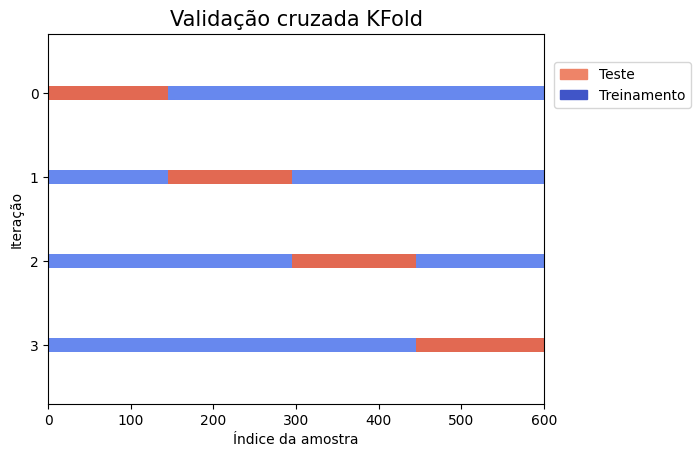

In [37]:
# Define a quantidade de iterações
K = 4
# Cria o objeto Kfold
cv = KFold(K)
# plot_cv_indices(cv, X_trein, Y_trein, K);
plot_cv_indices(cv, Xtre, Ytre, K);

#### Realizar validação cruzada KFold
O código a seguir realiza a validação cruzada $\text{Kfold}$. Utiliza o objeto $\text{cv}$ para criar as partições.

In [38]:
# Cria vetores de scores
accuracy_scores = []
f1_scores = []
# Realiza validação Kfol
for tr, tt in cv.split(Xtre, Ytre):
    X_tr = np.array(Xtre)[tr.astype(int)]
    Y_tr = np.array(Ytre)[tr.astype(int)]
    X_tt = np.array(Xtre)[tt.astype(int)]
    Y_tt = np.array(Ytre)[tt.astype(int)]
    clf.fit(X_tr, Y_tr)
    Y_prev = clf.predict(X_tt)
    acc = metrics.accuracy_score(Y_tt, Y_prev)
    # print(acc)
    accuracy_scores.append(acc)
    # print(accuracy_scores)
    f1 = metrics.f1_score(Y_tt, Y_prev, average='weighted')
    f1_scores.append(f1)

#### Plotar resultados da validação cruzada

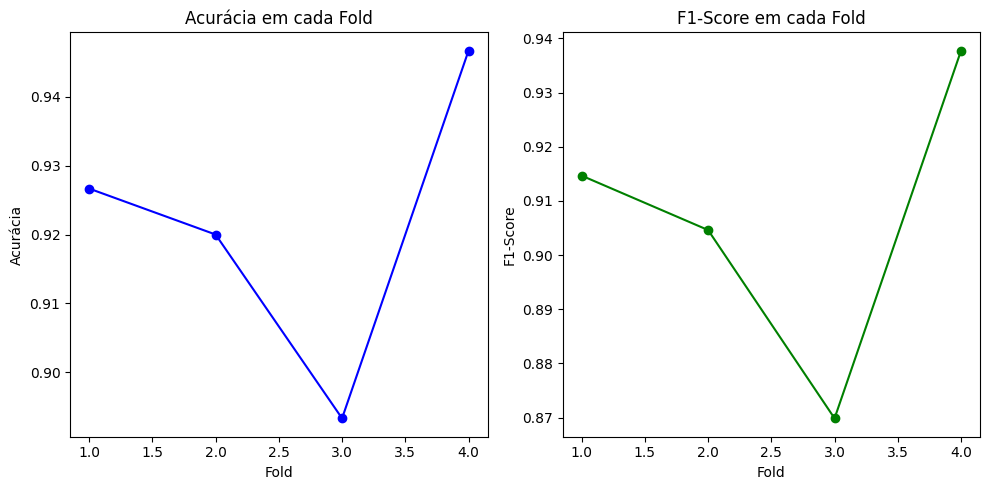

In [39]:
# Plotar resultados da validação cruzada
plt.figure(figsize=(10, 5))

# Plotar a acurácia para cada fold
plt.subplot(1, 2, 1)
plt.plot(range(1, len(accuracy_scores) + 1), accuracy_scores, marker ='o', linestyle='-', color='blue')
plt.xlabel('Fold')
plt.ylabel('Acurácia')
plt.title('Acurácia em cada Fold')

# Plotar a F1-score para cada fold
plt.subplot(1, 2, 2)
plt.plot(range(1, len(f1_scores) + 1), f1_scores, marker ='o', linestyle='-', color='green')
plt.xlabel('Fold')
plt.ylabel('F1-Score')
plt.title('F1-Score em cada Fold')

plt.tight_layout()
plt.show()

#### Imprimir média e desvio padrão das métricas da validação cruzada

In [40]:
print(f"Accuracy scores: {accuracy_scores}")
print("Média = %0.2f\nDesvio padrão = %0.2f" % (np.mean(accuracy_scores), np.std(accuracy_scores)))
print(f"\nF1_wa_scores: {f1_scores}")
print("Média = %0.2f\nDesvio padrão = %0.2f" % (np.mean(f1_scores), np.std(f1_scores)))

Accuracy scores: [0.9266666666666666, 0.92, 0.8933333333333333, 0.9466666666666667]
Média = 0.92
Desvio padrão = 0.02

F1_wa_scores: [0.9146666666666666, 0.9046218487394958, 0.8698507462686568, 0.9377370830608239]
Média = 0.91
Desvio padrão = 0.02


####  Função cross_val_score
A função cross_val_score realiza a validação cruzada ecalcula os scores automaticamente.<br>
Ela precisa que o classificador tenha sido treinado pela biblioteca sktearn.<br>
Usada aqui para conferir o algorimo anterior.

In [41]:
accuracy_scores = cross_val_score(clf, Xtre, Ytre, cv=cv, scoring='accuracy')
f1_scores = cross_val_score(clf, Xtre, Ytre, cv=cv, scoring='f1_weighted')
print(f"Accuracy scores: {accuracy_scores}")
print("Média = %0.2f\nDesvio padrão = %0.2f" % (np.mean(accuracy_scores), np.std(accuracy_scores)))
print(f"\nF1_scores: {f1_scores}")
print("Média = %0.2f\nDesvio padrão = %0.2f" % (np.mean(f1_scores), np.std(f1_scores)))

Accuracy scores: [0.92666667 0.92       0.89333333 0.94666667]
Média = 0.92
Desvio padrão = 0.02

F1_scores: [0.91466667 0.90462185 0.86985075 0.93773708]
Média = 0.91
Desvio padrão = 0.02


###  Comparação das métricas de teste e de avaliação cruzada
Imprimir as métricas accuracy e F1 resultantes da avaliação no conjunto de teste.<br>
Imprimir as médias das métricas accuracy e F1 resultantes da avaliação cruzada.<br><br>
**Observar que as métricas da validação cruzada são mais conservadoras do que as métricas da validação com o conjunto de teste.**

In [42]:
print("Comparação de métricas GaussianNB")
print("Avaliação com conjunto de teste: Accuracy = %0.4f  F1 = %0.4f" % (acc_teste_GNB, F1_teste_GNB))
print("Avaliação com validação cruzada: Accuracy = %0.4f  F1 = %0.4f" % (np.mean(f1_scores), np.mean(f1_scores)))

Comparação de métricas GaussianNB
Avaliação com conjunto de teste: Accuracy = 0.9275  F1 = 0.9122
Avaliação com validação cruzada: Accuracy = 0.9067  F1 = 0.9067


# Classificador GaussianMV
* Código do classificador GaussianNB.
* Calcular as métricas de classificação e comparar com o relatório produzido pela biblioteca sklearn.
* Plotar a matriz de confusão
* Realizar validação cruzada método KFold

### Classificador Gaussian

In [43]:
from scipy.stats import multivariate_normal
class GMV:
    def selecionarLimiar(self, Pval):
        # Iniciar os valores das variáveis locais
        melhorLimiar = 0
        melhorF1 = 0
        F1 = 0
        passo = (np.max(Pval) - np.min(Pval)) / 1000
        for limiar in np.arange(np.min(Pval), np.max(Pval), passo):
            Prev = (Pval < limiar).astype(np.float64)
            vp = np.count_nonzero(np.logical_and((Prev == 1),(self.Yval == 1)))
            fp = np.count_nonzero(np.logical_and((Prev == 1),(self.Yval == 0)))
            fn = np.count_nonzero(np.logical_and((Prev == 0),(self.Yval == 1)))
            if vp !=0:
                prec = vp/(vp+fp)  # cálculo de prec
                rec = vp/(vp+fn)   # cálculo de rec
                F1 = (2*prec*rec) / (prec+rec)  # cálculo de F1
            if F1 > melhorF1:
                melhorF1 = F1
                melhorLimiar = limiar
        return melhorLimiar

    def __init__(self, Xval, Yval):
        self.Xval = Xval
        self.Yval = Yval
        self.nmv = multivariate_normal(np.array([0, 0]), np.array([[1, 0],[0, 1]]))
        # self.F1 = float(0.0)
        self.Limiar = float(0.0)

    def fit(self, Xtre):
        self.nmv = multivariate_normal(Xtre.mean(axis=0), np.cov(Xtre.T))
        Pval = self.nmv.pdf(Xval)
        self.Limiar = self.selecionarLimiar(Pval)

    def predict(self, X_tt):
        Pval = self.nmv.pdf(X_tt)
        Yprev = (Pval < self.Limiar).astype(np.float64)
        return Yprev

### Classificação (criar classificador, ajustar, prever)

In [44]:
# Criar classificador
clf = GMV(Xval, Yval)
# Ajustar classificador
clf.fit(Xtre)
# Fazer previsões
Y_prev = clf.predict(X_test)

#### Calcular e imprimir métricas

In [45]:
# Calcular e imprimir accurary e f1 ponderado
# Colocar seu código aqui
# Acurácia
acc = metrics.accuracy_score(Y_test, Y_prev)
print(acc)
# F1 Score
F1 = metrics.f1_score(Y_test, Y_prev, average='weighted')
print(F1)

0.9775
0.978357625462117


#### Plotar matriz de confusão

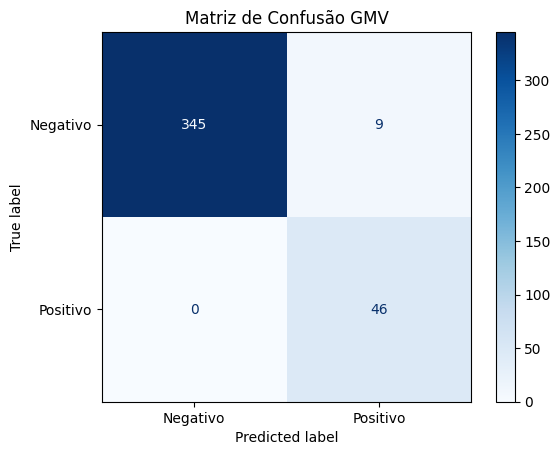

In [46]:
# PLotar matriz de confusão
# Colocar seu código aqui

# Gerar a matriz de confusão
mc = confusion_matrix(Y_test, Y_prev)

# Definir os nomes das classes (opcional, mas recomendado para clareza)
classes = ['Negativo', 'Positivo']

disp = ConfusionMatrixDisplay(confusion_matrix=mc, display_labels=classes)
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de Confusão GMV')
plt.show()

### Validação Cruzada

#### Realizar validação cruzada KFold
Não é necesário alterar o código a seguir

In [47]:
# Cria vetor de scores
accuracy_scores = []
f1_scores = []

# Realiza validação Kfold
# Colocar seu código aqui
for tr, tt in cv.split(Xtre, Ytre):
    X_tr = np.array(Xtre)[tr.astype(int)]
    Y_tr = np.array(Ytre)[tr.astype(int)]
    X_tt = np.array(Xtre)[tt.astype(int)]
    Y_tt = np.array(Ytre)[tt.astype(int)]
    # clf.fit(X_tr, Y_tr)
    clf.fit(X_tr)
    Y_prev = clf.predict(X_tt)
    acc = metrics.accuracy_score(Y_tt, Y_prev)
    # print(acc)
    accuracy_scores.append(acc)
    # print(accuracy_scores)
    f1 = metrics.f1_score(Y_tt, Y_prev, average='weighted')
    f1_scores.append(f1)

#### Imprimir média e desvio padrão das métricas da validação cruzada

In [48]:
# Colocar seu código aqui

print(f"Accuracy scores: {accuracy_scores}")
print("Média = %0.2f\nDesvio padrão = %0.2f" % (np.mean(accuracy_scores), np.std(accuracy_scores)))
print(f"\nF1_wa_scores: {f1_scores}")
print("Média = %0.2f\nDesvio padrão = %0.2f" % (np.mean(f1_scores), np.std(f1_scores)))

Accuracy scores: [0.9666666666666667, 0.9533333333333334, 0.98, 0.9733333333333334]
Média = 0.97
Desvio padrão = 0.01

F1_wa_scores: [0.967827903949577, 0.9561629243405377, 0.9801642409952029, 0.9747014595311808]
Média = 0.97
Desvio padrão = 0.01


####  Comparação das métricas de teste e de avaliação cruzada
Imprimir as métricas accuracy e F1 resultantes da avaliação no conjunto de teste.<br>
Imprimir as médias das métricas accuracy e F1 resultantes da avaliação cruzada.

In [49]:
# Colocar seu código aqui

print("Comparação de métricas GaussianNB")
print("Avaliação com conjunto de teste: Accuracy = %0.4f  F1 = %0.4f" % (acc, F1))
print("Avaliação com validação cruzada: Accuracy = %0.4f  F1 = %0.4f" % (np.mean(f1_scores), np.mean(f1_scores)))

Comparação de métricas GaussianNB
Avaliação com conjunto de teste: Accuracy = 0.9733  F1 = 0.9784
Avaliação com validação cruzada: Accuracy = 0.9697  F1 = 0.9697


# Conclusão

### Copiar aqui métricas de teste e de validação cruzada dos dois classificadores

#### GaussianNB

In [50]:
# Avaliação com conjunto de teste
# Accuracy = 0.9275
# F1 = 0.9122

# Avaliação com validação cruzada
# Accuracy = 0.9067
# F1 = 0.9067

#### GaussianMV

In [51]:
# Avaliação com conjunto de teste
# Accuracy = 0.9733
# F1 = 0.9784

# Avaliação com validação cruzada
# Accuracy = 0.9697
# F1 = 0.9697

### Escrever aqui suas conclusões sobre as avaliações

In [52]:
# Conclusões
# O Algorítimo MV foi melhor evidenciando que as variáveis possuem correlações
# enquanto o NB não considerando, teve um desempenho pior


## Entrega
Exportar para pdf.<br>
Renomear para Formativa03-nome-do-grupo.pdf<br>
Fazer upload no AVA.

In [53]:
#%%
##################################################################
######    Script para geração de pdf    ##########################
##################################################################

##################################################################
#######    Instalar bibliotecas         ##########################
##################################################################
!apt-get install texlive texlive-xetex texlive-latex-extra pandoc
!pip install pypandoc

##################################################################
#######   Copiar notebook para ambiente collab   #################
##################################################################
nome_notebook = nome +'.ipynb'
path_notebook = '/content/gdrive/MyDrive/Colab Notebooks/' + nome_notebook
!cp "{path_notebook}" ./

##################################################################
#######    Converter para pdf          ###########################
##################################################################
nome_notebook = nome +'.ipynb'
!jupyter nbconvert --to PDF "{nome_notebook}"

##################################################################
#######      Salvar no drive              ########################
##################################################################
nome_pdf = nome +'.pdf'
caminho_local = '/content/'+ nome_pdf
!cp "{caminho_local}" "{caminho_pdf}"

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  dvisvgm fonts-droid-fallback fonts-lato fonts-lmodern fonts-noto-mono
  fonts-texgyre fonts-urw-base35 libapache-pom-java
  libcmark-gfm-extensions0.29.0.gfm.3 libcmark-gfm0.29.0.gfm.3
  libcommons-logging-java libcommons-parent-java libfontbox-java libgs9
  libgs9-common libidn12 libijs-0.35 libjbig2dec0 libkpathsea6 libpdfbox-java
  libptexenc1 libruby3.0 libsynctex2 libteckit0 libtexlua53 libtexluajit2
  libwoff1 libzzip-0-13 lmodern pandoc-data poppler-data preview-latex-style
  rake ruby ruby-net-telnet ruby-rubygems ruby-webrick ruby-xmlrpc ruby3.0
  rubygems-integration t1utils teckit tex-common tex-gyre texlive-base
  texlive-binaries texlive-fonts-recommended texlive-latex-base
  texlive-latex-recommended texlive-pictures texlive-plain-generic tipa
  xfonts-encodings xfonts-utils
Suggested packages:
  fonts-noto fonts-freefont-